# 3 · Neuroscience plots  *(30 min)*

The plots you'll make most often, one at a time, with your style already applied. At the end, the things we
keep typing go into `style_parts/2_plots_color.mplstyle`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import neurodata

plt.style.use(["default", "style_parts/1_basics.mplstyle"])

## 1. Spike raster

`ax.eventplot` draws one row of ticks per trial. The stimulus was on from 0.5 to 1.5 s.

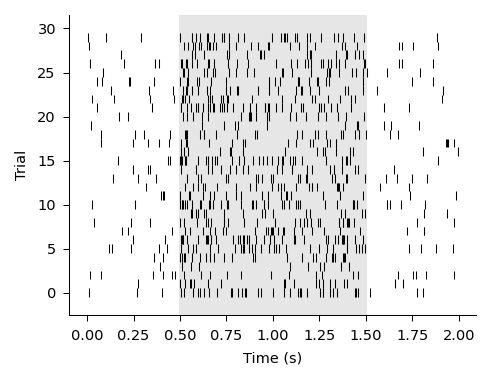

In [2]:
trials = neurodata.spike_trains(n_trials=30)

fig, ax = plt.subplots()
ax.eventplot(trials, colors="black", linewidths=0.5)
ax.axvspan(0.5, 1.5, color="0.9", zorder=0)
ax.set(xlabel="Time (s)", ylabel="Trial")
plt.show()

## 2. 🎛 PSTH

The peri-stimulus time histogram: spike counts in time bins, over all trials, converted to Hz.
How does the bin width change what you see?

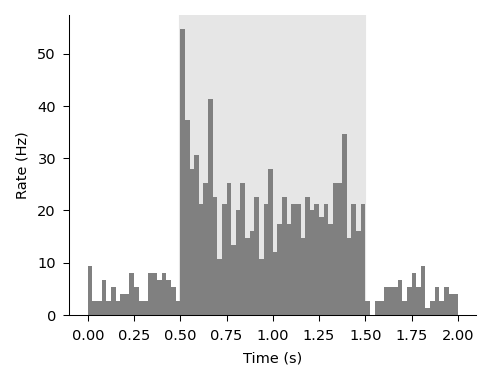

In [3]:
bin_ms = 25   # bin width in ms, try 5 to 200

width = bin_ms / 1000
edges = np.arange(0, 2 + width, width)
counts, _ = np.histogram(np.concatenate(trials), bins=edges)
fig, ax = plt.subplots()
ax.stairs(counts / (len(trials) * width), edges, fill=True, color="0.5")
ax.axvspan(0.5, 1.5, color="0.9", zorder=0)
ax.set(xlabel="Time (s)", ylabel="Rate (Hz)")
plt.show()

## 3. Tuning curves: mean ± SEM

`responses` has shape `(neurons, orientations, trials)`. `line, = ax.plot(...)` keeps the line, so the
shaded SEM can use the same color.

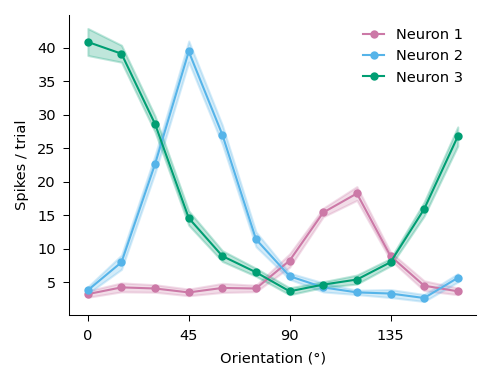

In [23]:
oris, responses = neurodata.orientation_tuning(n_neurons=3)
mean = responses.mean(axis=2)
sem = responses.std(axis=2) / np.sqrt(responses.shape[2])

fig, ax = plt.subplots()
for i in range(3):
    line, = ax.plot(oris, mean[i], marker="o", label=f"Neuron {i + 1}")
    ax.fill_between(oris, mean[i] - sem[i], mean[i] + sem[i], color=line.get_color(), alpha=0.25)
ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135])
ax.legend()
plt.show()

## 4. 🎛 Calcium imaging heatmap

`ax.imshow` draws a 2-D array (neurons × time) as an image. Try:
* `square_pixels = True`: that's the default, and why heatmaps often come out as a thin strip
* **colormaps**: does `jet` show structure that isn't there? (Hint: look for sharp "edges" between colors.)
* **vmax**: clip the brightest frames so the rest becomes visible

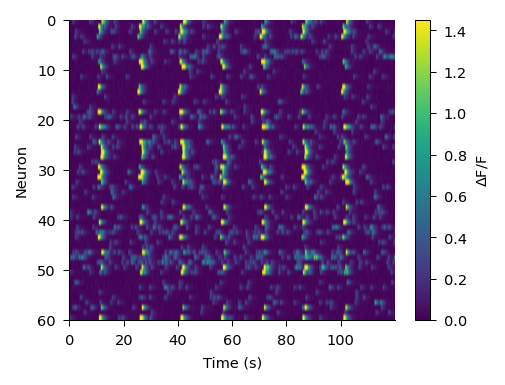

In [5]:
t_ca, dff, stim_times = neurodata.calcium_imaging()


cmap = "viridis"         # "viridis", "magma", "gray" or "jet"
vmax_percentile = 99.0   # try 90 to 100
square_pixels = False    # True or False

fig, ax = plt.subplots()
im = ax.imshow(dff, cmap=cmap, aspect="equal" if square_pixels else "auto",
               vmin=0, vmax=np.percentile(dff, vmax_percentile), extent=[0, t_ca[-1], len(dff), 0])
fig.colorbar(im, ax=ax, label=r"$\Delta F/F$")
ax.set(xlabel="Time (s)", ylabel="Neuron")
plt.show()

Exercise

Change the colour to magma 

Our eyes read **lightness** as "more". `jet` goes light-dark-light, which invents edges; `viridis` and
`magma` get steadily lighter. Rule of thumb:

| Data | Colormap |
|---|---|
| low → high (rate, ΔF/F) | `viridis`, `magma` |
| has a zero (correlation, change) | `RdBu_r`, with `vmin=-x, vmax=x` |
| wraps around (orientation, phase) | `twilight` |

## 5. Show every animal

Bar plots hide the data ([Weissgerber et al., 2015](https://doi.org/10.1371/journal.pbio.1002128)).
With few animals, show every point and connect paired measurements:

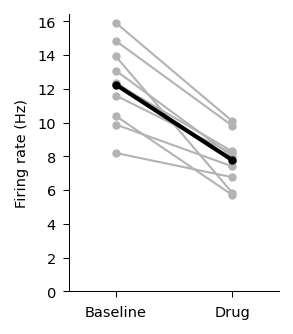

In [20]:
baseline, drug = neurodata.drug_experiment(n_animals=10)

fig, ax = plt.subplots(figsize=(1.8, 2.4))
ax.plot([0, 1], [baseline, drug], color="0.7", marker="o")
ax.plot([0, 1], [baseline.mean(), drug.mean()], color="black", marker="o", linewidth=2)
ax.set_xticks([0, 1], ["Baseline", "Drug"])
ax.set(xlim=(-0.4, 1.4), ylim=(0, None), ylabel="Firing rate (Hz)")
plt.show()

With more data, a box plot. Notice the median's random color 

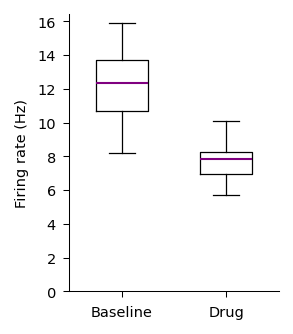

In [19]:
fig, ax = plt.subplots(figsize=(1.8, 2.4))
ax.boxplot([baseline, drug], widths=0.5)
ax.set_xticks([1, 2], ["Baseline", "Drug"])
ax.set(ylim=(0, None), ylabel="Firing rate (Hz)")
plt.show()

## 6. Colors everyone can see

About 1 in 12 men can't tell red from green well, and matplotlib's default colors put them next to each
other. The **Okabe–Ito** palette works for everyone. Tip: give each condition one color and use it in
**every** figure.

## 7. Write it down

In [21]:
%%writefile style_parts/2_plots_color.mplstyle
# ---- 2 · Plots and color -----------------------------------------------------
lines.markersize: 3
legend.handlelength: 1.5

# Heatmaps: fill the panel, perceptually uniform colormap
image.aspect: auto
image.cmap: viridis

# Okabe-Ito color-blind-safe colors (hex WITHOUT '#')
axes.prop_cycle: cycler('color', ['CC79A7','56B4E9', '009E73', 'D55E00', 'E69F00', '56B4E9' , '000000'])

# Box plots: black median, thin lines, small outliers
boxplot.medianprops.color: purple
boxplot.boxprops.linewidth: 0.6
boxplot.whiskerprops.linewidth: 0.6
boxplot.capprops.linewidth: 0.6
boxplot.flierprops.markersize: 2

Overwriting style_parts/2_plots_color.mplstyle


In [22]:
plt.style.use(["default", "style_parts/1_basics.mplstyle", "style_parts/2_plots_color.mplstyle"])

✏️ **Now scroll up and re-run** the tuning curve and the box plot cells. What changed?